In [ ]:
import deep_models.config as c
from deep_models.data import load_folds, make_splits, S00MILDataset
from torch.utils.data import DataLoader
from deep_models.vqvae import ConvVQVAE
from deep_models.vae_train import init_model, fit, plot_history

In [ ]:
split_k = 2

In [ ]:
developamental_folds = load_folds(c.dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")

train=1078  val=129  test=146


In [17]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

# Build & initialize model

In [ ]:
model = ConvVQVAE(latent_channels=16, code_book_size=64, commitment_cost=0.25, init_channels=16).to(c.device)
init_model(model, train_loader)

ConvVQVAE(
  (encoder): VQEncoder(
    (conv_1): Conv2d(5, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv_block1): DownBlock(
      (bn1): GroupNorm(8, 16, eps=1e-05, affine=True)
      (conv1): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (bn2): GroupNorm(8, 32, eps=1e-05, affine=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    )
    (conv_block2): DownBlock(
      (bn1): GroupNorm(8, 32, eps=1e-05, affine=True)
      (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (bn2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    )
    (res_block_1): ResBlock(
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (conv1): Conv2d(64, 6

# Train the model & save the best epoch's version

In [ ]:
history = fit(model, 
              train_loader, 
              val_loader, 
              epochs=50, 
              lr=1e-3, 
              ckpt_path=f"best_vqvae_split{split_k}.pt")

epoch   1/50  train 0.00672  val 0.00079  recon(SSE) 0.9408  VQ 0.00014  perp 20.1  R2 -0.204
epoch   2/50  train 0.00067  val 0.00060  recon(SSE) 0.8179  VQ 0.00004  perp 30.9  R2 -0.046
epoch   3/50  train 0.00057  val 0.00057  recon(SSE) 0.7923  VQ 0.00002  perp 38.9  R2 -0.014
epoch   4/50  train 0.00056  val 0.00056  recon(SSE) 0.7914  VQ 0.00001  perp 43.0  R2 -0.012
epoch   5/50  train 0.00055  val 0.00056  recon(SSE) 0.7912  VQ 0.00001  perp 46.5  R2 -0.012
epoch   6/50  train 0.00055  val 0.00055  recon(SSE) 0.7871  VQ 0.00001  perp 48.0  R2 -0.007
epoch   7/50  train 0.00055  val 0.00055  recon(SSE) 0.7889  VQ 0.00001  perp 49.2  R2 -0.009
epoch   8/50  train 0.00054  val 0.00055  recon(SSE) 0.7864  VQ 0.00001  perp 50.4  R2 -0.006
epoch   9/50  train 0.00054  val 0.00055  recon(SSE) 0.7906  VQ 0.00000  perp 50.1  R2 -0.011
epoch  10/50  train 0.00054  val 0.00055  recon(SSE) 0.7870  VQ 0.00000  perp 50.4  R2 -0.007
epoch  11/50  train 0.00054  val 0.00055  recon(SSE) 0.7904 

# Evaluate training history

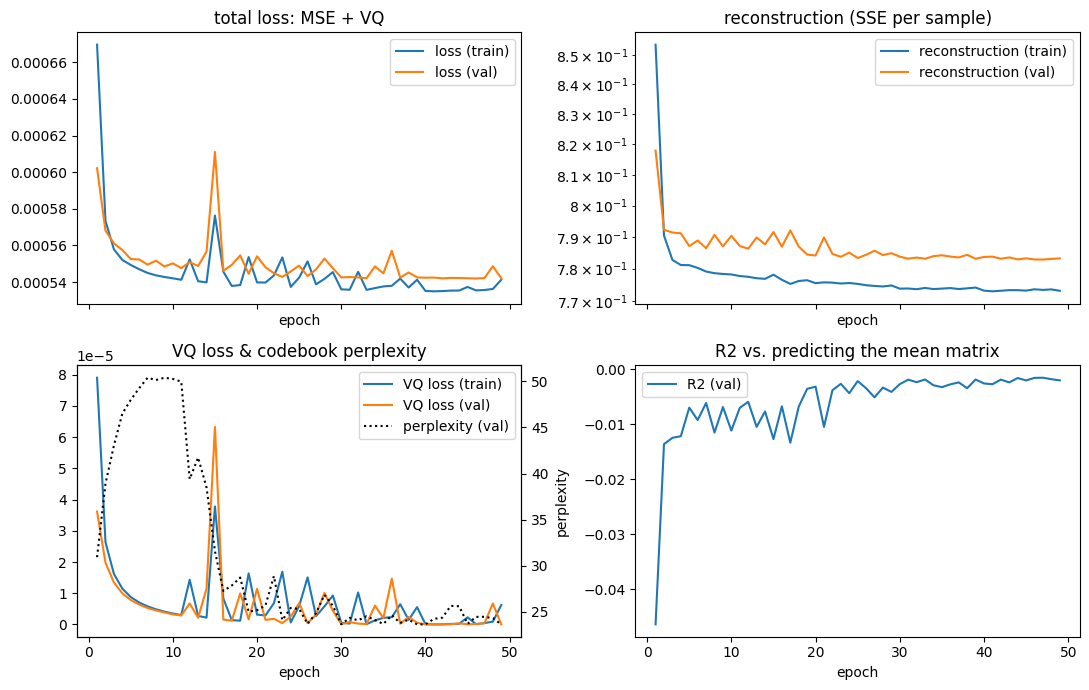

In [20]:
g = plot_history(history, skip=1)
g.show()